## Load 1D dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

In [2]:
df = pd.read_csv('/content/data_1d.csv')

print("First 5 rows of the dataset:")
display(df.head())

print("\nDataset Info:")
display(df.info())

print("\nDataset Description:")
display(df.describe())

First 5 rows of the dataset:


,x,y
0,1.049671,1
1,0.986174,1
2,1.064769,1
3,1.152303,1
4,0.976585,1



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       250 non-null    float64
 1   y       250 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 4.0 KB


None


Dataset Description:


,x,y
count,250.000000,250.000000
mean,2.999758,0.600000
std,1.426539,0.490881
min,0.804033,0.000000
25%,1.925611,0.000000
50%,3.004608,1.000000
75%,4.068459,1.000000
max,5.246324,1.000000


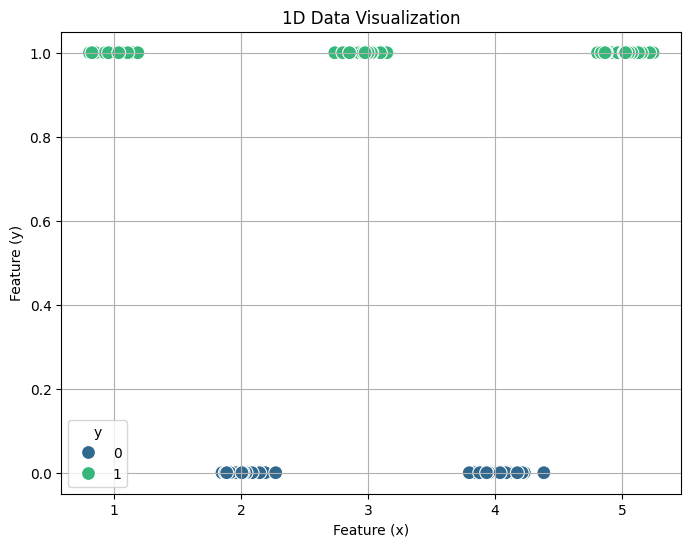

In [3]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='x', y='y', hue='y', data=df, s=100, palette='viridis')
plt.title('1D Data Visualization')
plt.xlabel('Feature (x)')
plt.ylabel('Feature (y)')
plt.grid(True)
plt.show()

In [26]:
X = np.array(df['x'])
y = np.array(df['y'])

Manually constructing a polynomial solution of the lowest degree achieving 100% accuracy. According to above figure, the thresholds where the function changes classes are 1.5, 2.5, 3.5, 4.5. These are the polynomial coefficients.

In [43]:
coef = np.array([1.5,2.5,3.5,4.5])
y_pred = (X-coef[0])*(X-coef[1])*(X-coef[2])*(X-coef[3])
y_pred = (y_pred >= 0).astype(int)
print(f"Accuracy for manually constructed polynomial with degree 4: {accuracy_score(y, y_pred)}")


Accuracy for manually constructed polynomial with degree 4: 1.0


The lowest Polynomial degree achieving 100% accuracy is 4

## Solving using Logistic Regression

In [47]:
def logistic_solution(X, y, deg=4):
    X_reshaped = X.reshape(-1, 1)
    model_pipeline = Pipeline([
        ('poly', PolynomialFeatures(degree=deg, include_bias=False)),
        ('logistic', LogisticRegression(max_iter=5000, C=1e3))
    ])
    model_pipeline.fit(X_reshaped, y)
    y_pred = model_pipeline.predict(X_reshaped)
    print(f"Accuracy for SKlearn Logistic Regression polynomial (degree={deg}) solution: {accuracy_score(y, y_pred)}")

logistic_solution(X, y)

Accuracy for SKlearn Logistic Regression polynomial (degree=4) solution: 1.0


## Testing higher model degrees' accuracies

In [48]:
for d in np.arange(1, 11):
    logistic_solution(X, y, deg=d)


Accuracy for SKlearn Logistic Regression polynomial (degree=1) solution: 0.6
Accuracy for SKlearn Logistic Regression polynomial (degree=2) solution: 0.732
Accuracy for SKlearn Logistic Regression polynomial (degree=3) solution: 0.74
Accuracy for SKlearn Logistic Regression polynomial (degree=4) solution: 1.0
Accuracy for SKlearn Logistic Regression polynomial (degree=5) solution: 1.0
Accuracy for SKlearn Logistic Regression polynomial (degree=6) solution: 1.0
Accuracy for SKlearn Logistic Regression polynomial (degree=7) solution: 1.0
Accuracy for SKlearn Logistic Regression polynomial (degree=8) solution: 1.0
Accuracy for SKlearn Logistic Regression polynomial (degree=9) solution: 1.0
Accuracy for SKlearn Logistic Regression polynomial (degree=10) solution: 1.0


As can be seen, the logistic regression model doesn't detoriate for degrees higher than 4

### Repeating steps 1-3 on 2D dataset

In [17]:
df = pd.read_csv('/content/data_2d.csv')

print("First 5 rows of the dataset:")
display(df.head())

print("\nDataset Info:")
display(df.info())

print("\nDataset Description:")
display(df.describe())

First 5 rows of the dataset:


,x1,x2,y
0,1.749080,2.901429,0
1,2.463988,2.197317,0
2,1.312037,1.311989,0
3,2.202230,2.416145,0
4,2.664885,1.424678,0



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 557 entries, 0 to 556
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      557 non-null    float64
 1   x2      557 non-null    float64
 2   y       557 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 13.2 KB


None


Dataset Description:


,x1,x2,y
count,557.000000,557.000000,557.000000
mean,3.386145,3.628895,0.718133
std,2.028163,1.960670,0.450313
min,0.044701,0.032424,0.000000
25%,1.600500,1.938144,0.000000
50%,3.301033,3.779898,1.000000
75%,5.156560,5.307669,1.000000
max,6.985539,6.998024,1.000000


### 2. Visualize 2D dataset

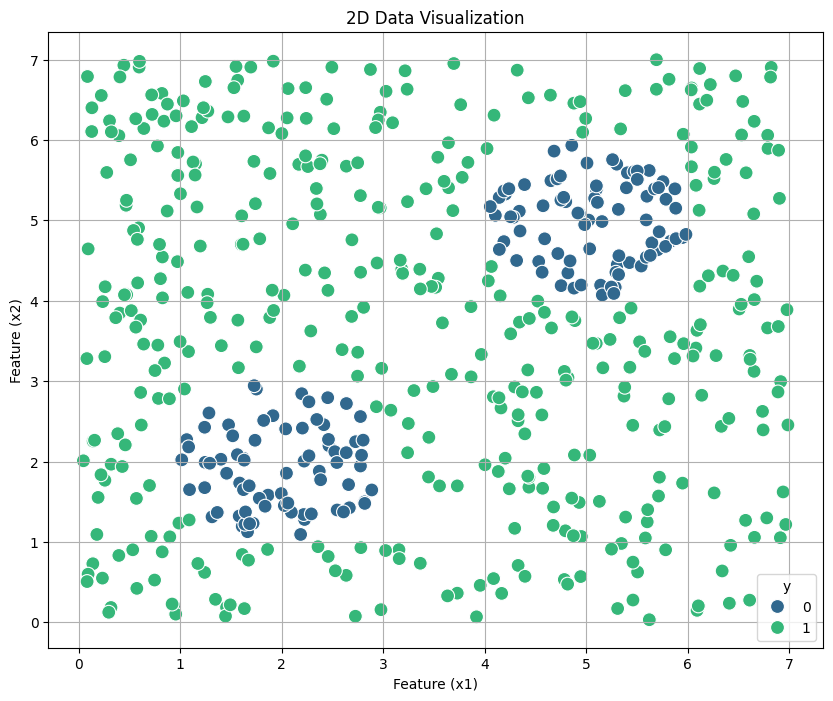

In [18]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x='x1', y='x2', hue='y', data=df, s=100, palette='viridis')
plt.title('2D Data Visualization')
plt.xlabel('Feature (x1)')
plt.ylabel('Feature (x2)')
plt.grid(True)
plt.show()

### 3. Prepare X and y for 2D dataset

In [19]:
X = np.array(df[['x1', 'x2']])
y = np.array(df['y'])


In [20]:
c1 = np.array([2, 2])
c2 = np.array([5, 5])

dist1_sq = ((X - c1)**2).sum(axis=1)
dist2_sq = ((X - c2)**2).sum(axis=1)

radius = 1
y_pred = (~((dist1_sq < radius**2) | (dist2_sq < radius**2))).astype(int)
print(f"Accuracy for manually constructed polynomial solution: {accuracy_score(y, y_pred)}")

Accuracy for manually constructed polynomial solution: 1.0


## The minimum degree for which a 100% accuracy is achived is 2 + 2 = 4.

## Solving using Logistic Regression

In [21]:
def logistic_solution_2d(X, y, deg=4):
    model_pipeline = Pipeline([
        ('poly', PolynomialFeatures(degree=deg, interaction_only=False, include_bias=False)),
        ('logistic', LogisticRegression(max_iter=10000, C=1e6))
    ])
    model_pipeline.fit(X, y)
    y_pred = model_pipeline.predict(X)
    print(f"Accuracy for SKlearn Logistic Regression polynomial (degree={deg}) solution: {accuracy_score(y, y_pred)}")
    return model_pipeline

logistic_solution_2d(X, y)

Accuracy for SKlearn Logistic Regression polynomial (degree=4) solution: 1.0


Pipeline(steps=[('poly', PolynomialFeatures(degree=4, include_bias=False)),
                ('logistic', LogisticRegression(C=1000000.0, max_iter=10000))])

In [22]:
for d in np.arange(1, 7):
    logistic_solution_2d(X, y, deg=d)

Accuracy for SKlearn Logistic Regression polynomial (degree=1) solution: 0.718132854578097
Accuracy for SKlearn Logistic Regression polynomial (degree=2) solution: 0.8617594254937163
Accuracy for SKlearn Logistic Regression polynomial (degree=3) solution: 0.8617594254937163
Accuracy for SKlearn Logistic Regression polynomial (degree=4) solution: 1.0
Accuracy for SKlearn Logistic Regression polynomial (degree=5) solution: 1.0
Accuracy for SKlearn Logistic Regression polynomial (degree=6) solution: 1.0


### Plotting Decision Boundaries for various Polynomial Degrees (1 to 4)

Accuracy for SKlearn Logistic Regression polynomial (degree=1) solution: 0.718132854578097
Accuracy for SKlearn Logistic Regression polynomial (degree=2) solution: 0.8617594254937163
Accuracy for SKlearn Logistic Regression polynomial (degree=3) solution: 0.8617594254937163
Accuracy for SKlearn Logistic Regression polynomial (degree=4) solution: 1.0


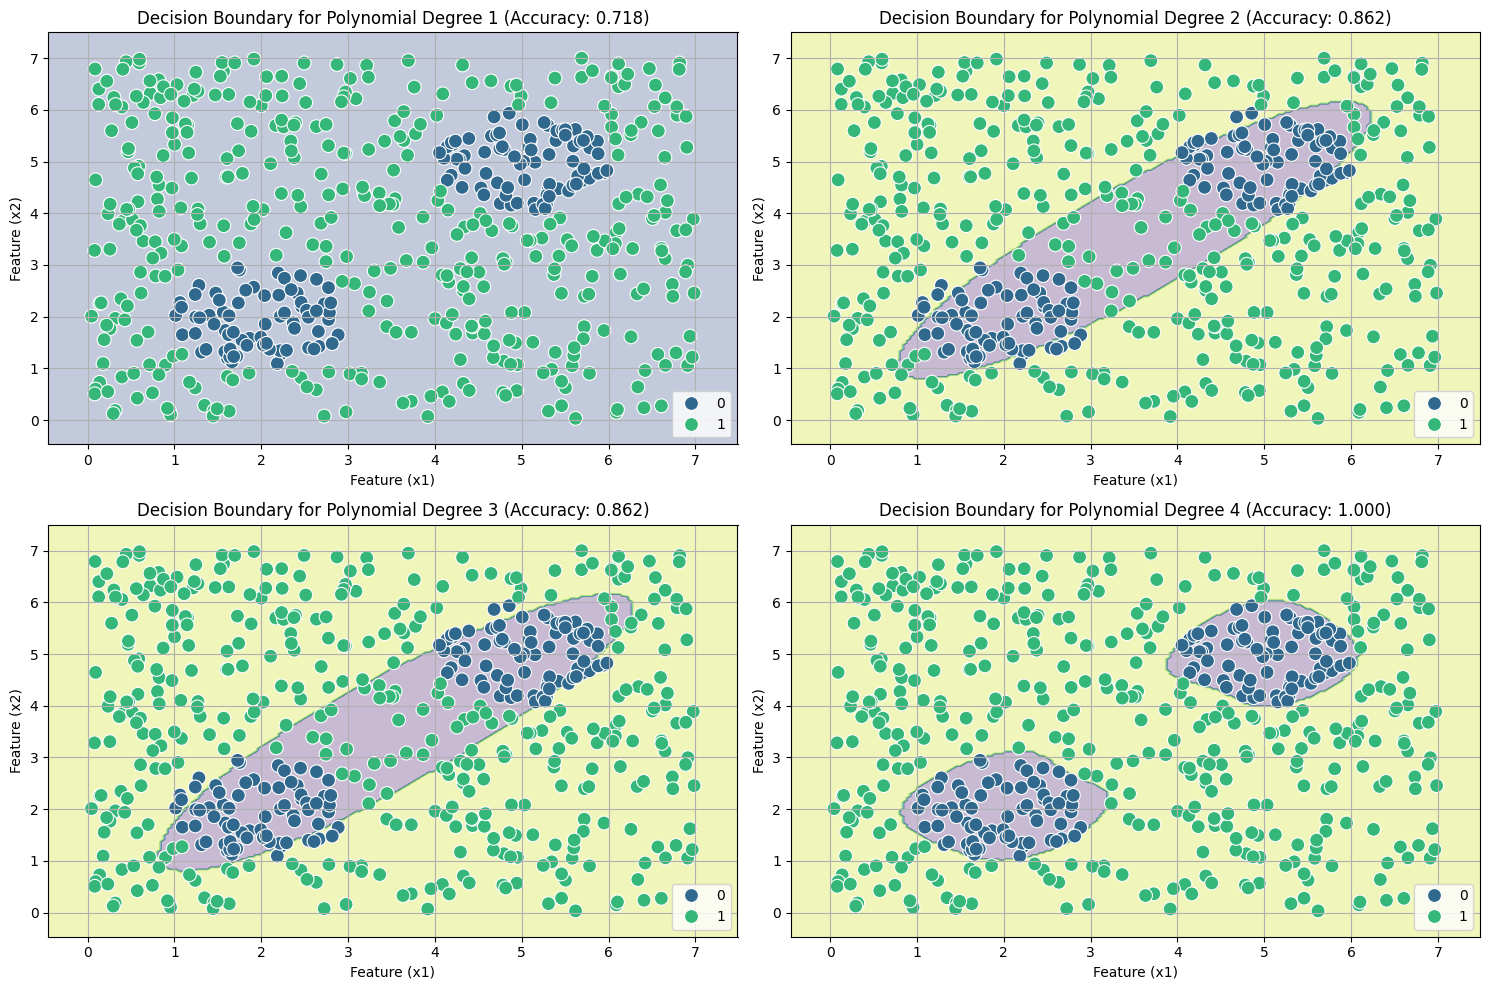

In [23]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, d in enumerate(range(1, 5)):
    model = logistic_solution_2d(X, y, deg=d)
    y_pred_accuracy = model.predict(X)
    accuracy = accuracy_score(y, y_pred_accuracy)

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, s=100, palette='viridis', legend='full', ax = axes[i])
    axes[i].set_title(f'Decision Boundary for Polynomial Degree {d} (Accuracy: {accuracy:.3f})')
    axes[i].set_xlabel('Feature (x1)')
    axes[i].set_ylabel('Feature (x2)')
    axes[i].grid(True)

plt.tight_layout()
plt.show()

# As can be seen, the decision boundary yielding to 100% accuracy is degree 4